# Build Your Own ChatGPT: LLM & Transformers From Scratch

In this notebook we build a **GPT-style Large Language Model** piece by piece, train it on Shakespeare,
and watch it learn to write.

| Part | Topic |
|---|---|
| 1 | The data |
| 2 | Tokenization: text to numbers |
| 3 | Training examples: predicting the next token |
| 4 | Embeddings: numbers to meaning |
| 5 | Self-attention by hand |
| 6 | Multi-head attention and the transformer block |
| 7 | The complete MiniGPT model |
| 8 | Training loop |
| 9 | Generating text with the trained model |
| 10 | Looking inside: attention maps |
| 11 | From MiniGPT to ChatGPT |

In [1]:
import sys, math, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import our minigpt package

import torch
import matplotlib.pyplot as plt

torch.manual_seed(1337)
plt.rcParams["figure.dpi"] = 110
print("PyTorch", torch.__version__, "| GPU available:", torch.cuda.is_available())

PyTorch 2.2.2+cpu | GPU available: False


## Part 1: The data

A language model learns from raw text. We use **Tiny Shakespeare**: about 1 million characters of plays.
You can swap in any `.txt` file: WhatsApp exports, Hindi poetry, legal contracts, source code...

In [2]:
from minigpt.data import download_tiny_shakespeare, load_text

text = load_text(download_tiny_shakespeare("../data/tinyshakespeare.txt"))
print(f"{len(text):,} characters")
print(text[:500])

1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## Part 2: Tokenization (text to numbers)

Neural networks only understand numbers. The simplest tokenizer gives every **character** its own id.

In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
print("vocabulary:", repr("".join(chars)))
print("vocab size:", vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}   # string  -> integer
itos = {i: ch for i, ch in enumerate(chars)}   # integer -> string
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

print(encode("Hi there!"))
print(decode(encode("Hi there!")))

vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
vocab size: 65
[20, 47, 1, 58, 46, 43, 56, 43, 2]
Hi there!


### How do GPT-4, Claude and LLaMA tokenize? Byte-Pair Encoding (BPE)

BPE starts from single bytes and repeatedly **merges the most frequent neighbouring pair** into a new token.
Common chunks like `the`, `ing`, ` and` become single tokens, so text gets much shorter.

In [4]:
from minigpt.tokenizer import BPETokenizer

bpe = BPETokenizer().train(text[:30_000], vocab_size=300)
print("first 15 merges learned:")
for (a, b), new_id in list(bpe.merges.items())[:15]:
    print(f"  {bpe.vocab[a]!r:>8} + {bpe.vocab[b]!r:<8} -> {bpe.vocab[new_id]!r}")

sample = "First Citizen: Before we proceed any further, hear me speak."
ids = bpe.encode(sample)
print("\ncharacters:", len(sample), "| BPE tokens:", len(ids))
print(bpe.token_strings(ids))

first 15 merges learned:


      b'e' + b' '     -> b'e '
      b't' + b'h'     -> b'th'
      b't' + b' '     -> b't '
      b's' + b' '     -> b's '
      b'o' + b'u'     -> b'ou'
      b',' + b' '     -> b', '
      b'd' + b' '     -> b'd '
      b'r' + b' '     -> b'r '
      b'i' + b'n'     -> b'in'
      b'a' + b'n'     -> b'an'
      b'e' + b'n'     -> b'en'
      b':' + b'\n'    -> b':\n'
      b'e' + b'r'     -> b'er'
      b'y' + b' '     -> b'y '
     b'\n' + b'\n'    -> b'\n\n'

characters: 60 | BPE tokens: 43
['F', 'i', 'r', 'st ', 'C', 'i', 'ti', 'z', 'en', ':', ' ', 'B', 'e', 'f', 'or', 'e ', 'w', 'e ', 'p', 'r', 'o', 'c', 'e', 'e', 'd ', 'an', 'y ', 'f', 'u', 'r', 'th', 'er', ', ', 'h', 'ea', 'r ', 'm', 'e ', 's', 'p', 'ea', 'k', '.']


In [5]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]          # 90% to learn from, 10% to check honesty
print(data.shape, data[:40])

torch.Size([1115394]) tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56])


## Part 3: Training examples (predict the next token)

From one chunk of text we get **many** training examples: at every position the target is simply the next character.

In [6]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(block_size):
    context, target = x[:t + 1], y[t]
    print(f"when input is {decode(context.tolist())!r:<12} the target is {decode([target.item()])!r}")

when input is 'F'          the target is 'i'
when input is 'Fi'         the target is 'r'
when input is 'Fir'        the target is 's'
when input is 'Firs'       the target is 't'
when input is 'First'      the target is ' '
when input is 'First '     the target is 'C'
when input is 'First C'    the target is 'i'
when input is 'First Ci'   the target is 't'


In [7]:
def get_batch(split, batch_size=4, block_size=8):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x, y

xb, yb = get_batch("train")
print("inputs:\n", xb)
print("targets:\n", yb)

inputs:
 tensor([[53, 59,  6,  1, 58, 56, 47, 40],
        [49, 43, 43, 54,  1, 47, 58,  1],
        [13, 52, 45, 43, 50, 53,  8,  0],
        [ 1, 39,  1, 46, 53, 59, 57, 43]])
targets:
 tensor([[59,  6,  1, 58, 56, 47, 40, 59],
        [43, 43, 54,  1, 47, 58,  1, 58],
        [52, 45, 43, 50, 53,  8,  0, 26],
        [39,  1, 46, 53, 59, 57, 43,  0]])


## Part 4: Embeddings (numbers to meaning)

An embedding is just a **lookup table**: row *i* is the learnable vector for token *i*.
A second table gives every **position** its own vector, because attention by itself has no sense of order.

In [8]:
from minigpt.layers import Embedding

n_embd = 16
token_emb = Embedding(vocab_size, n_embd)
pos_emb = Embedding(block_size, n_embd)

tok = token_emb(xb)                       # (B, T, C)
pos = pos_emb(torch.arange(block_size))   # (T, C)
x_in = tok + pos                          # broadcasting adds position to every sequence
print("token embeddings:", tok.shape, "| positions:", pos.shape, "| sum:", x_in.shape)

token embeddings: torch.Size([4, 8, 16]) | positions: torch.Size([8, 16]) | sum: torch.Size([4, 8, 16])


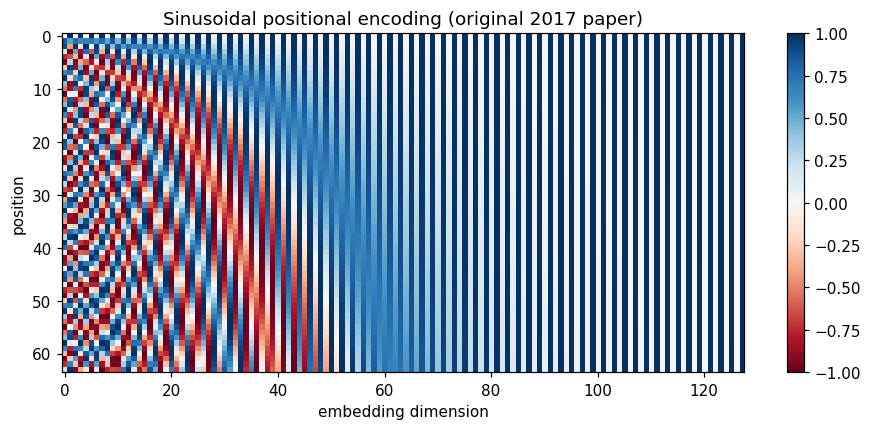

In [9]:
from minigpt.layers import SinusoidalPositionalEncoding

pe = SinusoidalPositionalEncoding(64, 128).pe
plt.figure(figsize=(10, 4))
plt.imshow(pe, cmap="RdBu", aspect="auto")
plt.xlabel("embedding dimension"); plt.ylabel("position")
plt.title("Sinusoidal positional encoding (original 2017 paper)")
plt.colorbar(); plt.show()

## Part 5: Self-attention by hand

### Step 1: the simplest way for a token to "listen" to the past is to average it
A lower-triangular matrix does this for every position at once.

In [10]:
T = 5
tril = torch.tril(torch.ones(T, T))
weights = tril / tril.sum(1, keepdim=True)
print(weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])


### Step 2: same result with masking and softmax
Blocked positions get `-inf`, and softmax turns `-inf` into exactly 0. This is the **causal mask**.

In [11]:
from minigpt.layers import softmax

scores = torch.zeros(T, T)
scores = scores.masked_fill(tril == 0, float("-inf"))
print(scores)
print(softmax(scores, dim=-1))

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])


### Step 3: real attention, with learned Query, Key and Value

* **Query**: what am I looking for?
* **Key**: what do I contain?
* **Value**: what will I share if you pick me?

$$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

In [12]:
from minigpt.layers import Linear

torch.manual_seed(42)
words = ["The", "cat", "sat", "on", "the", "mat"]
T, C, head_size = len(words), 32, 16
x = torch.randn(1, T, C)                      # pretend these are the embeddings of our 6 words

# std=0.3 gives visibly different random weights (the real model starts at 0.02 and learns)
query = Linear(C, head_size, bias=False, std=0.3)
key = Linear(C, head_size, bias=False, std=0.3)
value = Linear(C, head_size, bias=False, std=0.3)
q, k, v = query(x), key(x), value(x)          # (1, T, 16) each

scores = q @ k.transpose(-2, -1) / math.sqrt(head_size)   # (1, T, T): how well every query matches every key
mask = torch.tril(torch.ones(T, T))
scores = scores.masked_fill(mask == 0, float("-inf"))
att = softmax(scores, dim=-1)
out = att @ v                                              # weighted mix of values

print("attention weights:\n", att[0].detach().round(decimals=2))
print("output shape:", out.shape)

attention weights:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3100, 0.6700, 0.0200, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.5000, 0.0400, 0.4500, 0.0000, 0.0000],
        [0.6400, 0.0200, 0.0000, 0.0700, 0.2700, 0.0000],
        [0.4000, 0.0400, 0.5300, 0.0200, 0.0000, 0.0100]])
output shape: torch.Size([1, 6, 16])


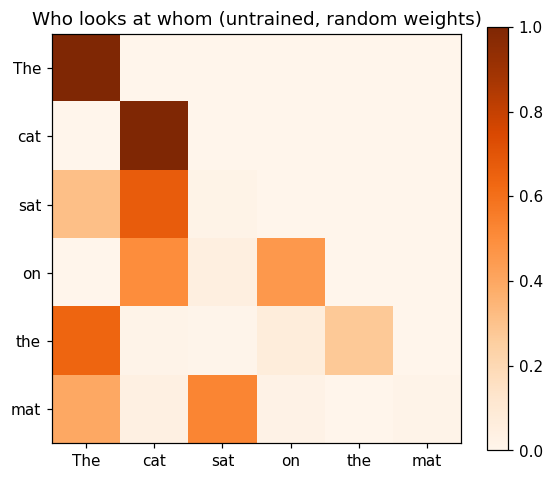

In [13]:
plt.figure(figsize=(6, 5))
plt.imshow(att[0].detach(), cmap="Oranges")
plt.xticks(range(T), words); plt.yticks(range(T), words)
plt.title("Who looks at whom (untrained, random weights)")
plt.colorbar(); plt.show()

### Why divide by $\sqrt{d_k}$?
Without scaling, dot products grow with the vector size, softmax becomes extremely peaky,
and gradients vanish. Scaling keeps the variance around 1.

In [14]:
a, b = torch.randn(1000, 64), torch.randn(1000, 64)
raw = (a * b).sum(-1)
print("variance without scaling:", raw.var().item())
print("variance with scaling:   ", (raw / math.sqrt(64)).var().item())

variance without scaling: 70.22491455078125
variance with scaling:    1.097264289855957


## Part 6: Multi-head attention and the transformer block

Several heads run in parallel, each free to learn a different pattern. Then a feed-forward network lets every
token "think" about what it gathered. **Residual connections** and **LayerNorm** keep deep stacks trainable.

```
x = x + Attention(LayerNorm(x))     # communicate
x = x + FeedForward(LayerNorm(x))   # compute
```

In [15]:
from minigpt.attention import MultiHeadAttention
from minigpt.model import TransformerBlock
from minigpt.config import GPTConfig

mha = MultiHeadAttention(n_embd=32, n_head=4, block_size=8, dropout=0.0)
xb_emb = torch.randn(2, 8, 32)
print("multi-head attention:", xb_emb.shape, "->", mha(xb_emb).shape)

block = TransformerBlock(GPTConfig(n_embd=32, n_head=4, block_size=8, dropout=0.0))
print("transformer block:   ", xb_emb.shape, "->", block(xb_emb).shape)

multi-head attention: torch.Size([2, 8, 32]) -> torch.Size([2, 8, 32])
transformer block:    torch.Size([2, 8, 32]) -> torch.Size([2, 8, 32])


## Part 7: The complete MiniGPT

In [16]:
from minigpt import MiniGPT

cfg = GPTConfig(vocab_size=vocab_size, block_size=128, n_layer=4, n_head=4, n_embd=192, dropout=0.1)
model = MiniGPT(cfg)
print(f"total parameters: {model.num_parameters():,}\n")
for name, module in model.named_children():
    n = sum(p.numel() for p in module.parameters())
    print(f"{name:<20} {n:>10,}")

total parameters: 1,829,376

token_embedding          12,480
position_embedding       24,576
dropout                       0
blocks                1,779,456
ln_f                        384
lm_head                  12,480


In [17]:
xb, yb = get_batch("train", batch_size=4, block_size=128)
logits, loss = model(xb, yb)
print("logits shape:", logits.shape, "  (batch, time, vocab)")
print(f"loss before training: {loss.item():.3f}   expected for random guessing: ln(65) = {math.log(65):.3f}")

start = torch.tensor([encode("ROMEO:")])
print("\nuntrained model says:\n", decode(model.generate(start, 120)[0].tolist()))

logits shape: torch.Size([4, 128, 65])   (batch, time, vocab)
loss before training: 4.141   expected for random guessing: ln(65) = 4.174



untrained model says:
 ROMEO:jkTTzpOvrEZp IbOzN J&dmMwtXZewKXCpuxsdhcrjx
Bm
cShK:
-Vkk&U!RG3i. VBH3qaMOsYqIuKQAbtkv!:jhJy'k?aHXI3CoCqFX.XziTA;qEOB!Ac


## Part 8: Training loop

The whole of deep learning in five lines: **batch -> forward -> loss -> backward -> update**.
Here we run a short demo on a smaller model. The full model is trained with `python train.py`.

step   0 | loss 4.182


step  50 | loss 2.669


step 100 | loss 2.527


step 150 | loss 2.451


step 200 | loss 2.340


step 250 | loss 2.308


done in 13s


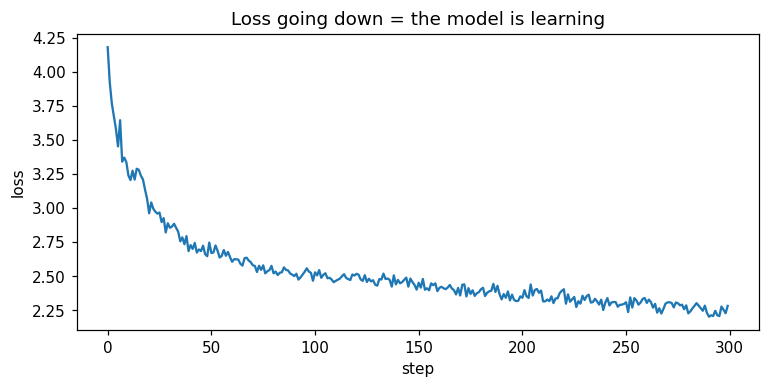

In [18]:
from minigpt.optim import AdamW
import time

small = MiniGPT(GPTConfig(vocab_size=vocab_size, block_size=64, n_layer=2, n_head=4, n_embd=64, dropout=0.0))
optimizer = AdamW(small.parameters(), lr=3e-3)
losses, t0 = [], time.time()

for step in range(300):
    xb, yb = get_batch("train", batch_size=32, block_size=64)
    logits, loss = small(xb, yb)        # 1. forward
    optimizer.zero_grad()
    loss.backward()                     # 2. backward (autograd computes every gradient)
    optimizer.step()                    # 3. update
    losses.append(loss.item())
    if step % 50 == 0:
        print(f"step {step:3d} | loss {loss.item():.3f}")
print(f"done in {time.time() - t0:.0f}s")

plt.figure(figsize=(8, 3.5)); plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss")
plt.title("Loss going down = the model is learning"); plt.show()

In [19]:
print(decode(small.generate(torch.tensor([encode("ROMEO:")]), 200, temperature=0.8)[0].tolist()))

ROMEO:
Nons, ar that, loud, and Gas Mand bry the thinct dis whank.


SAURCARINS:
Se what wn pat hou sof your she dlit;
The my me wit om thit wor wham. Hend thang counge I fald blit inkn is
Som win the mor t


## Part 9: The fully trained MiniGPT

This checkpoint was produced by `python train.py` (2,500 steps, about 30 minutes on a laptop CPU).

step 2500 | validation loss 1.573


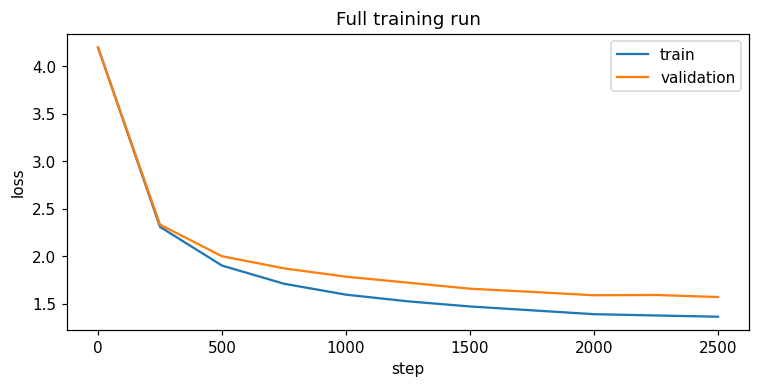

In [20]:
import json
from minigpt import load_checkpoint

trained, tok, ckpt = load_checkpoint("../checkpoints/minigpt.pt")
print(f"step {ckpt['step']} | validation loss {ckpt['val_loss']:.3f}")

hist = json.load(open("../checkpoints/history.json"))
plt.figure(figsize=(8, 3.5))
plt.plot(hist["step"], hist["train"], label="train"); plt.plot(hist["step"], hist["val"], label="validation")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("Full training run"); plt.show()

In [21]:
torch.manual_seed(7)
prompt = torch.tensor([tok.encode("ROMEO:\n")])
print(tok.decode(trained.generate(prompt, 500, temperature=0.8, top_k=40)[0].tolist()))

ROMEO:
How to must in the
right of his brother's earness, if you no content;
And as the present of my lord,
In of your noble heavens commands you.

FRIAR LAURENCE:
Your grains my designess to full me of thrive,
But which you have like to my mother children
With seem of the arm.

RIVERS:
Once with of him a picial part to shall day
He have did the friends of the bloodening heart
Whence I shall go friend the gives of the judgment.

BRUTUS:
You that make as fast I play to thee with thee.

CAMILLO:
So made 


### Temperature: the creativity knob

In [22]:
for t in [0.3, 1.0, 1.6]:
    torch.manual_seed(0)
    out = trained.generate(torch.tensor([tok.encode("JULIET:\n")]), 150, temperature=t)
    print(f"===== temperature {t} =====")
    print(tok.decode(out[0].tolist()), "\n")

===== temperature 0.3 =====
JULIET:
Why, sir, what we may shall be so may be and
To with the country of the son of the conscession,
And the great of the children of the provost,
That we  



===== temperature 1.0 =====
JULIET:
Why shall dare was, yet I will presently
And with to my guilty hands, and, your tractio;
That rather, we thought oft and repent:
Tell him, how like yo 



===== temperature 1.6 =====
JULIET:
Go, may, time in givy, quick'st changeobles!
How moody Thus godsalive! ho, usar: graquiCt
And rathly, weign my spoker heir perlabouy. God, Pomlet's
wr 



### What does the model think comes next?

In [23]:
context = "To be, or not to b"
probs = trained.next_token_probs(torch.tensor([tok.encode(context)]))[0]
top = torch.topk(probs, 8)
for p, i in zip(top.values, top.indices):
    print(f"{tok.decode([i.item()])!r:>6}  {p.item():6.1%}  " + "#" * int(p.item() * 60))

   'e'   72.9%  ###########################################
   'r'    6.3%  ###
   'u'    6.0%  ###
   'l'    5.1%  ###
   'a'    3.4%  ##
   'o'    2.2%  #
   'i'    2.0%  #
   'y'    2.0%  #


## Part 10: Looking inside: attention maps of the trained model

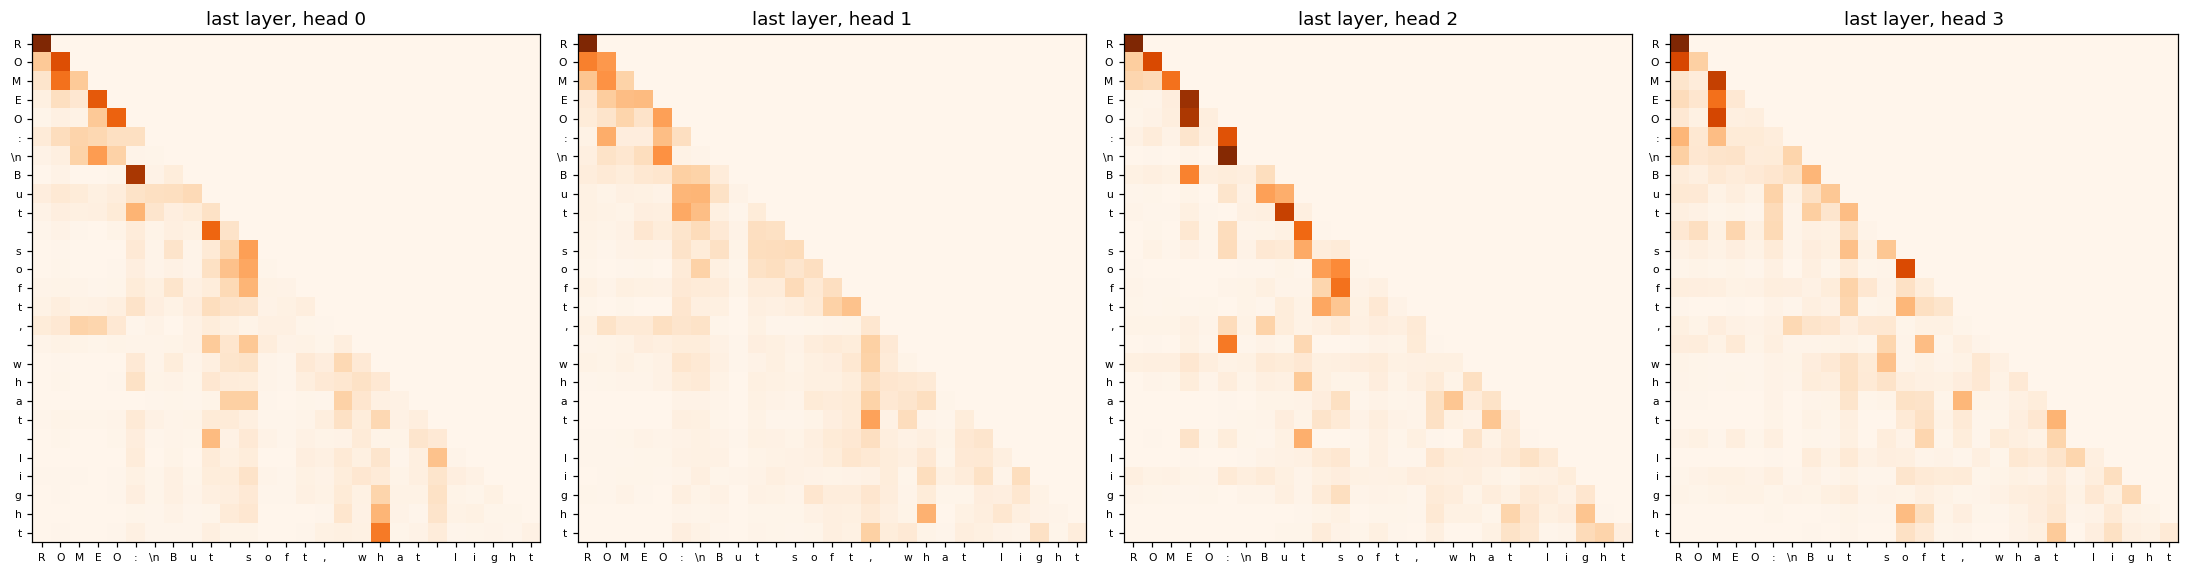

In [24]:
line = "ROMEO:\nBut soft, what light"
trained(torch.tensor([tok.encode(line)]))
maps = trained.attention_maps()
labels = [c if c != "\n" else "\\n" for c in line]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
for h, ax in enumerate(axes):
    ax.imshow(maps[-1][0, h], cmap="Oranges")
    ax.set_xticks(range(len(labels)), labels, fontsize=7); ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.set_title(f"last layer, head {h}")
plt.tight_layout(); plt.show()

## Part 11: From MiniGPT to ChatGPT

| Stage | MiniGPT (this course) | ChatGPT-class models |
|---|---|---|
| Architecture | decoder-only transformer | the **same** decoder-only transformer |
| Size | 1.8 M parameters | hundreds of billions |
| Tokenizer | 65 characters | ~100k BPE tokens |
| Data | 1 MB of Shakespeare | trillions of tokens of web, books, code |
| Hardware | one laptop CPU, 30 min | thousands of GPUs, months |
| Step 2: fine-tuning | none | supervised fine-tuning on conversations |
| Step 3: alignment | none | RLHF / RLAIF so answers are helpful and safe |

**You now understand the engine inside every modern AI assistant.**